# CS 412 — Chicago Airbnb Price Prediction: Intermediate Experiment

**Goal:** Produce a *real* dataset summary and preliminary comparison of Linear Regression, Random Forest, and XGBoost, following our proposal. The three feature groups are (1) baseline, (2) baseline + location, and (3) baseline + location + amenities.

**Dataset:** Inside Airbnb, detailed Chicago listings snapshot, **September 19, 2026** ([source](https://insideairbnb.com/get-the-data/)). Target = advertised listing **nightly price**, not actual booked revenue. Use the detailed `listings.csv.gz`, not the smaller summary `listings.csv`.

Run the cells **top to bottom** with the project's `.venv` kernel. The detailed Chicago `listings.csv.gz` must be in the project's `data/` folder. All tables and figures are written to `results/`.

**Every number comes from running this notebook on the dataset.** This is a preliminary, untuned comparison on a single 80/20 split; do not present it as the final model evaluation.

**Sections:** 1 load data · 1b raw schema · 2 clean price · 3 feature sets · 4 EDA · 5 train and evaluate 9 configurations · 6 feature-group comparison · 7 answers to the comparison questions · 8 diagnostics · 9 saved outputs

## 1 — Check libraries and load the data

**Setup:** Put `listings.csv.gz` in the project's `data/` folder. Create the virtual environment and install dependencies from the project root (`python3 -m venv .venv`, then `.venv/bin/pip install -r requirements.txt`). On macOS, also run `brew install libomp` for XGBoost. Select `.venv` as the notebook kernel.

The first cell prints library versions for reproducibility. The second finds the project root, loads the raw data, and creates `results/`.


In [1]:
# Install once from the project root: pip install -r requirements.txt
# On macOS, XGBoost also needs the OpenMP runtime: brew install libomp
import platform

import matplotlib
import numpy
import pandas
import sklearn
import xgboost

print('Python', platform.python_version())
for module in (pandas, numpy, sklearn, xgboost, matplotlib):
    print(f'{module.__name__:12s} {module.__version__}')

Python 3.13.3
pandas       3.1.0
numpy        2.5.4
sklearn      1.9.1
xgboost      3.4.1
matplotlib   3.11.2


In [2]:
import ast
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_STATE = 42

# Works whether the kernel starts in the project root or in notebooks/.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'listings.csv.gz').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f'Could not find data/listings.csv.gz in {Path.cwd()} or any parent folder. '
        'Put the Inside Airbnb detailed listings file in the project data/ folder.'
    )
DATA_PATH = PROJECT_ROOT / 'data' / 'listings.csv.gz'
RESULTS_DIR = PROJECT_ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok=True)

raw = pd.read_csv(DATA_PATH, compression='gzip', low_memory=False)
print('Loaded:', DATA_PATH)
print('Saving outputs to:', RESULTS_DIR)
print(f'Raw dataset: {len(raw):,} listings, {len(raw.columns)} columns')

PROPOSAL_COLUMNS = ['price', 'room_type', 'property_type', 'accommodates', 'bedrooms', 'bathrooms', 'bathrooms_text',
                    'beds', 'host_is_superhost', 'number_of_reviews', 'review_scores_rating', 'minimum_nights',
                    'latitude', 'longitude', 'neighbourhood_cleansed', 'amenities']
missing_columns = [c for c in PROPOSAL_COLUMNS if c not in raw.columns]
print('Proposal columns missing from the file:', missing_columns or 'none')


Matplotlib is building the font cache; this may take a moment.


Loaded: /Users/haiha/Documents/UIC/Fall 2026/CS 412/data/listings.csv.gz
Saving outputs to: /Users/haiha/Documents/UIC/Fall 2026/CS 412/results
Raw dataset: 8,695 listings, 90 columns
Proposal columns missing from the file: none


## 1b — Inspect the raw schema

Shape, data types, and missing values for the raw file, with a closer look at the columns the proposal needs. The target is `price` (advertised nightly price, stored as text). The full per-column overview is saved to `results/raw_column_overview.csv`.

In [3]:
print(f'Raw dataset: {raw.shape[0]:,} rows x {raw.shape[1]} columns')
print('Snapshot (last_scraped):', raw['last_scraped'].min(), 'to', raw['last_scraped'].max())
print('Column dtypes:', raw.dtypes.astype(str).value_counts().to_dict())
print('\nAll columns:', ', '.join(raw.columns))

raw_overview = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'missing_percent': (raw.isna().mean() * 100).round(1),
    'n_unique': raw.nunique(),
})
raw_overview.to_csv(RESULTS_DIR / 'raw_column_overview.csv', index_label='column')
print('\nEntirely empty columns:', raw_overview.index[raw_overview['missing_percent'] == 100].tolist())

print('\nColumns needed for the proposal features (raw data):')
display(raw_overview.loc[[c for c in PROPOSAL_COLUMNS if c in raw.columns]])
print('Example raw values:')
display(raw[['price', 'bathrooms_text', 'host_is_superhost', 'amenities']].head(3))

Raw dataset: 8,695 rows x 90 columns
Snapshot (last_scraped): 2026-09-19 to 2026-09-20
Column dtypes: {'float64': 37, 'str': 29, 'int64': 24}

All columns: id, listing_url, scrape_id, last_scraped, source, name, description, neighborhood_overview, picture_url, host_id, host_url, host_profile_id, host_profile_url, host_name, host_since, hosts_time_as_user_years, hosts_time_as_user_months, hosts_time_as_host_years, hosts_time_as_host_months, host_location, host_about, host_response_time, host_response_rate, host_acceptance_rate, host_is_superhost, host_thumbnail_url, host_picture_url, host_neighbourhood, host_listings_count, host_total_listings_count, host_verifications, host_has_profile_pic, host_identity_verified, neighbourhood, neighbourhood_cleansed, neighbourhood_group_cleansed, latitude, longitude, property_type, room_type, accommodates, bathrooms, bathrooms_text, bedrooms, beds, amenities, price, price_quote_checkin_date, price_quote_checkout_date, price_quote_total_price, price_q


Entirely empty columns: ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'instant_bookable']

Columns needed for the proposal features (raw data):


,dtype,missing_percent,n_unique
price,str,14.3,4375
room_type,str,0.0,4
property_type,str,0.0,43
accommodates,int64,0.0,16
bedrooms,float64,0.0,16
bathrooms,float64,100.0,0
bathrooms_text,str,0.4,35
beds,float64,2.6,21
host_is_superhost,str,0.0,2
number_of_reviews,int64,0.0,504


Example raw values:


,price,bathrooms_text,host_is_superhost,amenities
0,$177.33,1 bath,f,"[""Free parking on premises"", ""Smoke alarm"", ""T..."
1,NaN,2 baths,f,"[""Lake access""]"
2,$50.77,1 shared bath,f,"[""Smoke alarm"", ""Fire extinguisher"", ""Carbon m..."


## 2 — Clean nightly price and basic features

**Document every filtering choice.**
- `price` is stored as text such as `"$1,250.00"`; `$` and `,` are stripped and the value is converted to a number. Unparseable values become missing.
- Listings with a missing price are **removed**, not imputed: price is the target, and listings with no advertised price are typically inactive or unavailable, so an imputed target would be invented data.
- Nonpositive prices are removed as invalid.
- Prices are restricted to **$20–$1,500** per night as an explicit preliminary outlier rule (a modeling choice, *not* an official dataset requirement). Extreme values dominate squared-error training and RMSE. This rule is applied before the split, so the test set uses the same price range.

The row counts for each step are saved to `results/filtering_log.csv`. Missing *feature* values are not dropped here; they are imputed inside the training pipeline (Section 5).

In [4]:
PRICE_MIN, PRICE_MAX = 20, 1500

df = raw.copy()
if 'price' not in df.columns:
    raise ValueError("Detailed listings data with a 'price' column required. Did you download the summary listings.csv instead?")
df['price'] = pd.to_numeric(df['price'].astype(str).str.replace(r'[$,]', '', regex=True), errors='coerce')

missing_price = df['price'].isna()
nonpositive_price = df['price'] <= 0
below_min = (df['price'] > 0) & (df['price'] < PRICE_MIN)
above_max = df['price'] > PRICE_MAX
filtering_log = pd.DataFrame({
    'Step': ['Raw listings', 'Removed: missing or unparseable price', 'Removed: price <= 0',
             f'Removed: 0 < price < ${PRICE_MIN}', f'Removed: price > ${PRICE_MAX:,}', 'Retained listings'],
    'Rows': [len(df), missing_price.sum(), nonpositive_price.sum(), below_min.sum(), above_max.sum(),
             df['price'].between(PRICE_MIN, PRICE_MAX).sum()],
})
display(filtering_log)
filtering_log.to_csv(RESULTS_DIR / 'filtering_log.csv', index=False)

df = df.loc[df['price'].between(PRICE_MIN, PRICE_MAX)].copy()
print(f'Retained {len(df):,} / {len(raw):,} rows ({len(df) / len(raw):.1%})')
print(df['price'].describe().round(2).to_string())


,Step,Rows
0,Raw listings,8695
1,Removed: missing or unparseable price,1243
2,Removed: price <= 0,0
3,Removed: 0 < price < $20,10
4,"Removed: price > $1,500",69
5,Retained listings,7373


Retained 7,373 / 8,695 rows (84.8%)
count    7373.00
mean      268.53
std       213.23
min        22.64
25%       130.50
50%       207.50
75%       340.12
max      1500.00


## 3 — Create the three proposed feature groups

| Proposal feature | Column used | Type |
|---|---|---|
| Property type | `property_type` | categorical (one-hot) |
| Room type | `room_type` | categorical (one-hot) |
| Bedrooms / Beds | `bedrooms`, `beds` | numeric |
| Bathrooms | `bathrooms`, **parsed from `bathrooms_text`** | numeric |
| Guest capacity | `accommodates` | numeric |
| Superhost status | `host_is_superhost` (`t`/`f`) | categorical (one-hot) |
| Number of reviews / Review rating | `number_of_reviews`, `review_scores_rating` | numeric |
| Minimum nights | `minimum_nights` | numeric |
| Latitude / Longitude | `latitude`, `longitude` | numeric |
| Neighborhood | `neighbourhood_cleansed` | categorical (one-hot) |
| Distance from central Chicago | `distance_to_chicago_center_km` (engineered) | numeric |
| Amenity indicators | `amenity_wifi`, `_parking`, `_air_conditioning`, `_kitchen`, `_washer`, `_dryer`, `_pool` (engineered) | binary |
| Total number of amenities | `amenity_count` (engineered) | numeric |

**Schema adjustments (documented deviations):**
- **Bathrooms.** The `bathrooms` column exists but is 100% empty in this snapshot. The count is parsed from `bathrooms_text` (e.g. `"1.5 shared baths"` → 1.5; `"Half-bath"` → 0.5). The shared/private wording is not used, to keep the baseline as proposed.
- **Neighborhood** uses `neighbourhood_cleansed` (Inside Airbnb's standardized community-area name), not the free-text `neighbourhood` field.
- **Distance** is the haversine distance in km to a downtown reference point (41.8781, −87.6298, the Loop).
- **Washer/dryer** from the proposal is kept as two separate indicators, `amenity_washer` and `amenity_dryer`.
- **Amenity matching** is done per amenity string with word boundaries. Simple substring matching would have counted "Dishwasher" (a washer), "Hair dryer" (a dryer), and "Pool table"/"Whirlpool" appliances (a pool), which are very common in this data. "Parking" includes free and paid, on- and off-premises, and street parking. "Air conditioning" also covers "Window AC unit" and ductless AC. "Kitchen" means a full kitchen or kitchenette, not outdoor kitchens or appliance brands such as KitchenAid.

In [5]:
base_numeric = ['accommodates', 'bedrooms', 'bathrooms', 'beds', 'number_of_reviews', 'review_scores_rating', 'minimum_nights']
base_categorical = ['room_type', 'property_type', 'host_is_superhost']
loc_numeric = ['latitude', 'longitude', 'distance_to_chicago_center_km']
loc_categorical = ['neighbourhood_cleansed']

# --- Bathrooms: this snapshot ships an empty `bathrooms` column; the count is only in `bathrooms_text`.
def parse_bathrooms(text):
    if pd.isna(text):
        return np.nan
    text = str(text).lower()
    if 'half-bath' in text:
        return 0.5
    match = re.search(r'\d+(?:\.\d+)?', text)
    return float(match.group()) if match else np.nan

if 'bathrooms' not in df.columns or df['bathrooms'].isna().all():
    df['bathrooms'] = df['bathrooms_text'].map(parse_bathrooms)
print(f"bathrooms parsed from bathrooms_text: {df['bathrooms'].notna().sum():,} values, {df['bathrooms'].isna().sum()} missing")

for column in base_numeric + ['latitude', 'longitude']:
    df[column] = pd.to_numeric(df[column], errors='coerce')

# --- Location: great-circle (haversine) distance to downtown Chicago.
CHICAGO_CENTER = (41.8781, -87.6298)
lat1, lon1 = np.radians(df['latitude']), np.radians(df['longitude'])
lat2, lon2 = np.radians(CHICAGO_CENTER[0]), np.radians(CHICAGO_CENTER[1])
a = np.sin((lat1 - lat2) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon1 - lon2) / 2) ** 2
df['distance_to_chicago_center_km'] = 6371.0 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

# --- Amenities: a JSON list of free-text strings per listing.
def parse_amenities(value):
    if pd.isna(value):
        return []
    try:
        parsed = json.loads(value)
    except (TypeError, ValueError):
        try:
            parsed = ast.literal_eval(str(value))
        except (SyntaxError, ValueError):
            return []
    return [str(item).strip().lower() for item in parsed] if isinstance(parsed, list) else []

# Matched per amenity item with word boundaries: plain substring matching would count
# "dishwasher" as a washer, "hair dryer" as a dryer, and "pool table"/"whirlpool" as a pool.
AMENITY_RULES = {
    'wifi': (r'wifi', None),
    'parking': (r'parking', None),
    'air_conditioning': (r'air conditioning|\bac\b', None),
    'kitchen': (r'^(?:private |shared )?kitchen(?:ette)?$', None),
    'washer': (r'\bwasher\b', None),
    'dryer': (r'\bdryer\b', r'hair dryer'),
    'pool': (r'\bpool\b', r'pool table'),
}

def has_amenity(items, include, exclude):
    return int(any(re.search(include, item) and not (exclude and re.search(exclude, item)) for item in items))

amenity_lists = df['amenities'].map(parse_amenities)
for feature, (include, exclude) in AMENITY_RULES.items():
    df[f'amenity_{feature}'] = amenity_lists.map(lambda items: has_amenity(items, include, exclude))
df['amenity_count'] = amenity_lists.map(len)

amenity_numeric = [f'amenity_{name}' for name in AMENITY_RULES] + ['amenity_count']
amenity_prevalence = (df[amenity_numeric[:-1]].mean() * 100).round(1).rename('percent_of_listings')
print('\nAmenity indicator prevalence (% of retained listings):')
print(amenity_prevalence.to_string())
print(f"Amenities per listing: median {df['amenity_count'].median():.0f}, range {df['amenity_count'].min()}–{df['amenity_count'].max()}")
amenity_prevalence.to_csv(RESULTS_DIR / 'amenity_prevalence.csv', index_label='amenity')

# Fail loudly rather than silently changing the research design if important columns are missing.
required = base_numeric + base_categorical + loc_numeric + loc_categorical + amenity_numeric
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Expected fields absent: {missing}. Inspect raw.columns and adjust with documented rationale.")
feature_sets = {
    'Baseline': (base_numeric, base_categorical),
    'Baseline + location': (base_numeric + loc_numeric, base_categorical + loc_categorical),
    'Baseline + location + amenities': (base_numeric + loc_numeric + amenity_numeric, base_categorical + loc_categorical),
}
print('Rows:', len(df))
for name, (nums, cats) in feature_sets.items():
    print(name, ':', len(nums), 'numeric +', len(cats), 'categorical fields')


bathrooms parsed from bathrooms_text: 7,341 values, 32 missing



Amenity indicator prevalence (% of retained listings):
amenity_wifi                99.0
amenity_parking             82.1
amenity_air_conditioning    95.3
amenity_kitchen             92.1
amenity_washer              76.9
amenity_dryer               71.2
amenity_pool                 7.6
Amenities per listing: median 43, range 0–96
Rows: 7373
Baseline : 7 numeric + 3 categorical fields
Baseline + location : 10 numeric + 4 categorical fields
Baseline + location + amenities : 18 numeric + 4 categorical fields


## 4 — Exploratory data analysis (EDA)

Dataset summary, missing values among the model inputs, descriptive statistics, and three figures: the price distribution (linear and log scale), price by room type, and a map of listings colored by price. Use the **actual output** below for the dataset description in the report.

,Statistic,Value
0,Snapshot date (last_scraped),2026-09-19 to 2026-09-20
1,Raw listings,8695
2,Raw columns,90
3,Retained listings,7373
4,Retained share of raw listings (%),84.8
5,Median nightly price (USD),207.5
6,Mean nightly price (USD),268.53
7,Std. dev. nightly price (USD),213.23
8,Min nightly price (USD),22.64
9,Max nightly price (USD),1500.0


Missing values (%) among retained listings (imputed inside the training pipeline):
review_scores_rating    12.5
beds                     2.5
minimum_nights           1.1
bathrooms                0.4

Numeric feature statistics (retained listings):


,count,mean,std,min,25%,50%,75%,max
accommodates,7373.0,4.73,3.22,1.00,2.00,4.00,6.00,16.00
bedrooms,7372.0,1.93,1.29,0.00,1.00,2.00,3.00,13.00
bathrooms,7341.0,1.46,0.82,0.00,1.00,1.00,2.00,25.00
beds,7190.0,2.56,1.95,1.00,1.00,2.00,3.00,21.00
number_of_reviews,7373.0,73.16,112.23,0.00,5.00,33.00,96.00,2450.00
review_scores_rating,6455.0,4.77,0.35,1.00,4.72,4.86,4.96,5.00
minimum_nights,7293.0,11.07,20.12,1.00,2.00,2.00,32.00,365.00
latitude,7373.0,41.89,0.06,41.65,41.86,41.90,41.94,42.02
longitude,7373.0,-87.66,0.05,-87.85,-87.69,-87.66,-87.63,-87.53
distance_to_chicago_center_km,7373.0,7.36,4.67,0.07,3.40,6.82,10.61,26.51


Room types: {'Entire home/apt': 5673, 'Private room': 1597, 'Hotel room': 80, 'Shared room': 23}
Superhost: {'t': 3755, 'f': 3618}
Distinct property types: 41, neighbourhoods: 75


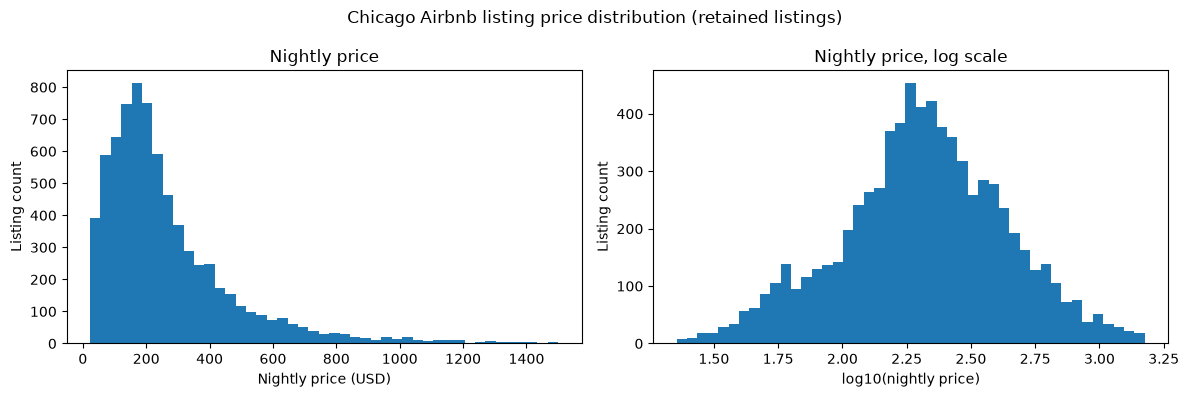

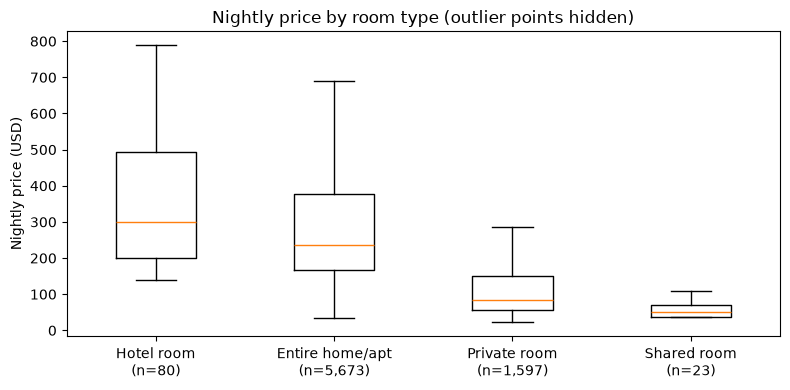

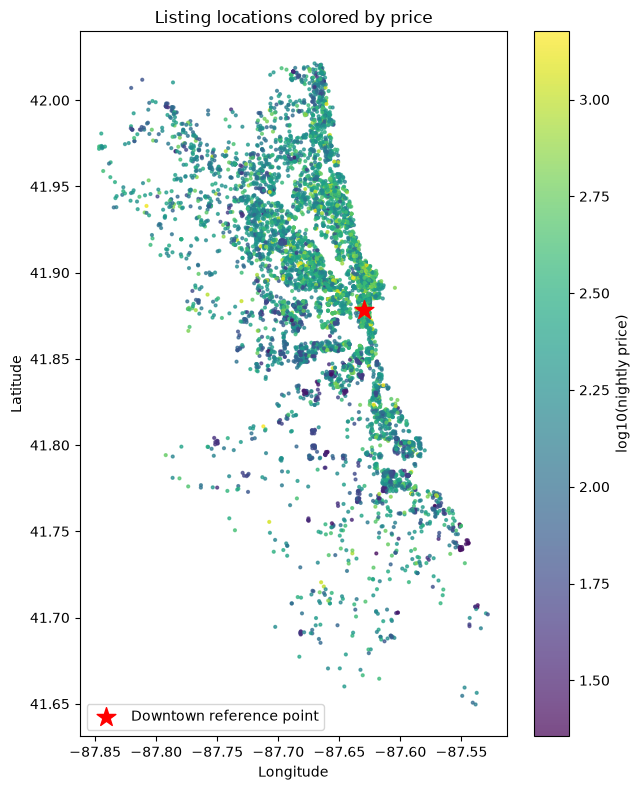

In [6]:
summary = pd.DataFrame({
    'Statistic': ['Snapshot date (last_scraped)', 'Raw listings', 'Raw columns', 'Retained listings',
                  'Retained share of raw listings (%)', 'Median nightly price (USD)', 'Mean nightly price (USD)',
                  'Std. dev. nightly price (USD)', 'Min nightly price (USD)', 'Max nightly price (USD)'],
    'Value': [f"{raw['last_scraped'].min()} to {raw['last_scraped'].max()}", len(raw), raw.shape[1], len(df),
              round(100 * len(df) / len(raw), 1), round(df.price.median(), 2), round(df.price.mean(), 2),
              round(df.price.std(), 2), round(df.price.min(), 2), round(df.price.max(), 2)],
})
display(summary)
summary.to_csv(RESULTS_DIR / 'dataset_summary.csv', index=False)

model_inputs = base_numeric + base_categorical + loc_numeric + loc_categorical + amenity_numeric
missingness = (df[model_inputs].isna().mean() * 100).sort_values(ascending=False).round(1)
print('Missing values (%) among retained listings (imputed inside the training pipeline):')
print(missingness[missingness > 0].to_string())
missingness.rename('missing_percent').to_csv(RESULTS_DIR / 'missingness.csv', index_label='feature')

print('\nNumeric feature statistics (retained listings):')
display(df[base_numeric + loc_numeric + ['amenity_count', 'price']].describe().T.round(2))
print('Room types:', df['room_type'].value_counts().to_dict())
print('Superhost:', df['host_is_superhost'].value_counts().to_dict())
print(f"Distinct property types: {df['property_type'].nunique()}, neighbourhoods: {df['neighbourhood_cleansed'].nunique()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['price'], bins=45)
axes[0].set(xlabel='Nightly price (USD)', ylabel='Listing count', title='Nightly price')
axes[1].hist(np.log10(df['price']), bins=45)
axes[1].set(xlabel='log10(nightly price)', ylabel='Listing count', title='Nightly price, log scale')
fig.suptitle('Chicago Airbnb listing price distribution (retained listings)')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'chicago_price_distribution.png', dpi=160)
plt.show()

room_order = df.groupby('room_type')['price'].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([df.loc[df['room_type'] == r, 'price'] for r in room_order], showfliers=False)
ax.set_xticks(range(1, len(room_order) + 1), [f'{r}\n(n={(df.room_type == r).sum():,})' for r in room_order])
ax.set(ylabel='Nightly price (USD)', title='Nightly price by room type (outlier points hidden)')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'price_by_room_type.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 8))
points = ax.scatter(df['longitude'], df['latitude'], c=np.log10(df['price']), s=4, cmap='viridis', alpha=0.7)
ax.scatter([CHICAGO_CENTER[1]], [CHICAGO_CENTER[0]], marker='*', s=200, color='red', label='Downtown reference point')
fig.colorbar(points, ax=ax, label='log10(nightly price)')
ax.set(xlabel='Longitude', ylabel='Latitude', title='Listing locations colored by price')
ax.legend(loc='lower left')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'price_map.png', dpi=160)
plt.show()

## 5 — Train and evaluate 3 models × 3 feature sets

All nine comparisons use the **same 80/20 train/test row split** (`random_state=42`), so differences between configurations come from the features and algorithms, not from different test rows.

**Leakage control.** Every configuration is one scikit-learn `Pipeline` whose preprocessing is fitted on the training rows only, then applied unchanged to the test rows:
- Numeric features: missing values → training-set **median** (robust to the heavy right skew of counts such as `number_of_reviews` and `minimum_nights`).
- Categorical features: missing values → training-set **most frequent** category, then **one-hot encoding**. Categories that appear only in the test rows are encoded as all zeros (`handle_unknown='ignore'`).
- Numeric features are not scaled: tree models are scale-invariant, and unregularized linear regression gives the same predictions with or without scaling.

The feature-engineering steps in Section 3 (bathroom parsing, distance, amenity flags) only use each listing's own row, so computing them before the split does not leak information.

**Models (reasonable defaults, not tuned):** Linear Regression; Random Forest (120 trees, `min_samples_leaf=2`); XGBoost (180 trees, depth 5, learning rate 0.06, 90% row/column subsampling). A *predict-the-training-mean* reference is printed for context; it is not one of the nine configurations.

**Metrics** on the test rows: MAE and RMSE in USD (lower is better; RMSE penalizes large misses more) and R² (higher is better).

In [7]:
import time

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

train_idx, test_idx = train_test_split(df.index.to_numpy(), test_size=0.2, random_state=RANDOM_STATE)
y_train = df.loc[train_idx, 'price']
y_test = df.loc[test_idx, 'price']
print(f'Train rows: {len(train_idx):,}   Test rows: {len(test_idx):,}')

naive_preds = np.full(len(y_test), y_train.mean())
naive_mae = mean_absolute_error(y_test, naive_preds)
naive_rmse = np.sqrt(mean_squared_error(y_test, naive_preds))
print(f'Reference (predict training mean ${y_train.mean():.2f}): MAE ${naive_mae:.2f}, RMSE ${naive_rmse:.2f}, R2 {r2_score(y_test, naive_preds):.4f}')

models = {
    'Linear Regression': lambda: LinearRegression(),
    'Random Forest': lambda: RandomForestRegressor(
        n_estimators=120, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost': lambda: XGBRegressor(
        n_estimators=180, max_depth=5, learning_rate=0.06, subsample=0.9, colsample_bytree=0.9,
        objective='reg:squarederror', tree_method='hist', n_jobs=2, random_state=RANDOM_STATE),
}

results, predictions, fitted = [], {}, {}
for fs_name, (numeric, categorical) in feature_sets.items():
    preprocess = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), numeric),
        ('categorical', Pipeline([
            ('fill', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore')),
        ]), categorical),
    ])
    X_train = df.loc[train_idx, numeric + categorical]
    X_test = df.loc[test_idx, numeric + categorical]
    for model_name, factory in models.items():
        pipeline = Pipeline([('preprocess', clone(preprocess)), ('regressor', factory())])
        start = time.perf_counter()
        pipeline.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - start
        preds = pipeline.predict(X_test)
        if not np.isfinite(preds).all():
            raise ValueError(f'Non-finite predictions from {model_name} on {fs_name}')
        predictions[(fs_name, model_name)] = preds
        fitted[(fs_name, model_name)] = pipeline
        entry = {
            'Feature set': fs_name, 'Model': model_name,
            'Model inputs after encoding': len(pipeline.named_steps['preprocess'].get_feature_names_out()),
            'MAE': round(mean_absolute_error(y_test, preds), 2),
            'RMSE': round(np.sqrt(mean_squared_error(y_test, preds)), 2),
            'R2': round(r2_score(y_test, preds), 4),
            'Train rows': len(train_idx), 'Test rows': len(test_idx),
            'Fit seconds': round(fit_seconds, 2),
        }
        results.append(entry)
        print(f"{fs_name:33s} {model_name:18s} MAE {entry['MAE']:8.2f}  RMSE {entry['RMSE']:8.2f}  R2 {entry['R2']:.4f}")

results_df = pd.DataFrame(results)
if len(results_df) != 9:
    raise ValueError(f'Expected 9 configurations, got {len(results_df)}')
display(results_df)
results_df.to_csv(RESULTS_DIR / 'preliminary_results.csv', index=False)


Train rows: 5,898   Test rows: 1,475
Reference (predict training mean $269.72): MAE $152.34, RMSE $215.43, R2 -0.0008
Baseline                          Linear Regression  MAE   103.45  RMSE   160.64  R2 0.4435


Baseline                          Random Forest      MAE    90.21  RMSE   148.38  R2 0.5252


Baseline                          XGBoost            MAE    89.57  RMSE   145.90  R2 0.5410
Baseline + location               Linear Regression  MAE    97.45  RMSE   149.69  R2 0.5168


Baseline + location               Random Forest      MAE    79.25  RMSE   135.53  R2 0.6039


Baseline + location               XGBoost            MAE    81.32  RMSE   135.12  R2 0.6063


Baseline + location + amenities   Linear Regression  MAE    97.29  RMSE   147.94  R2 0.5280


Baseline + location + amenities   Random Forest      MAE    78.53  RMSE   135.03  R2 0.6068


Baseline + location + amenities   XGBoost            MAE    77.74  RMSE   130.81  R2 0.6310


,Feature set,Model,Model inputs after encoding,MAE,RMSE,R2,Train rows,Test rows,Fit seconds
0,Baseline,Linear Regression,53,103.45,160.64,0.4435,5898,1475,0.09
1,Baseline,Random Forest,53,90.21,148.38,0.5252,5898,1475,3.88
2,Baseline,XGBoost,53,89.57,145.90,0.5410,5898,1475,0.44
3,Baseline + location,Linear Regression,131,97.45,149.69,0.5168,5898,1475,0.11
4,Baseline + location,Random Forest,131,79.25,135.53,0.6039,5898,1475,6.07
5,Baseline + location,XGBoost,131,81.32,135.12,0.6063,5898,1475,0.70
6,Baseline + location + amenities,Linear Regression,139,97.29,147.94,0.5280,5898,1475,0.24
7,Baseline + location + amenities,Random Forest,139,78.53,135.03,0.6068,5898,1475,9.11
8,Baseline + location + amenities,XGBoost,139,77.74,130.81,0.6310,5898,1475,0.47


## 6 — Compare location and amenities against baseline

For each model and metric: the gain from adding location (Set 1 → Set 2) and the *additional* gain from adding amenities on top of location (Set 2 → Set 3). Percentages are relative to the baseline value of that error metric; they are left blank for R², where the absolute change is the meaningful quantity.

,Model,Metric,Baseline,Baseline + location,Baseline + location + amenities,Location improvement,Amenities additional improvement,Location improvement (% of baseline),Amenities additional improvement (% of baseline)
0,Linear Regression,MAE,103.4500,97.4500,97.2900,6.0000,0.1600,5.8,0.2
1,Linear Regression,RMSE,160.6400,149.6900,147.9400,10.9500,1.7500,6.8,1.1
2,Linear Regression,R2,0.4435,0.5168,0.5280,0.0733,0.0112,NaN,NaN
3,Random Forest,MAE,90.2100,79.2500,78.5300,10.9600,0.7200,12.1,0.8
4,Random Forest,RMSE,148.3800,135.5300,135.0300,12.8500,0.5000,8.7,0.3
5,Random Forest,R2,0.5252,0.6039,0.6068,0.0787,0.0029,NaN,NaN
6,XGBoost,MAE,89.5700,81.3200,77.7400,8.2500,3.5800,9.2,4.0
7,XGBoost,RMSE,145.9000,135.1200,130.8100,10.7800,4.3100,7.4,3.0
8,XGBoost,R2,0.5410,0.6063,0.6310,0.0653,0.0247,NaN,NaN


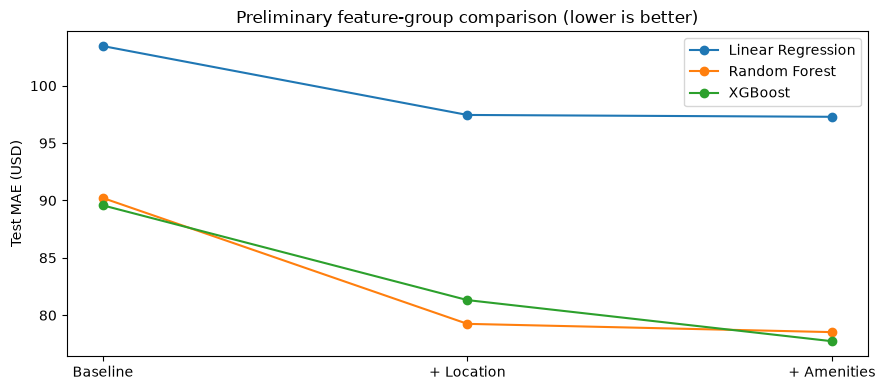

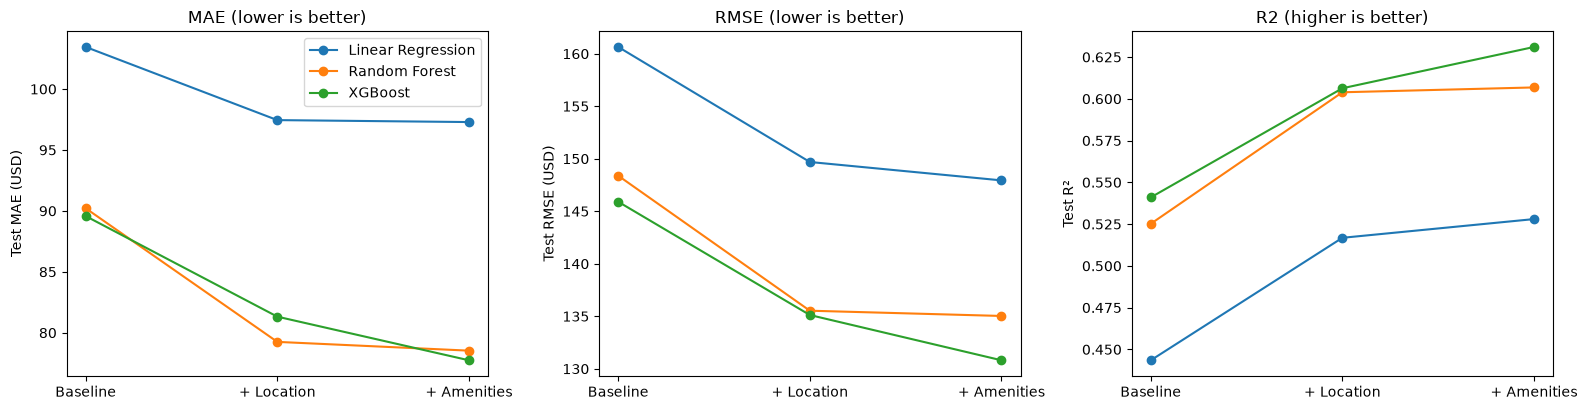

In [8]:
METRICS = ['MAE', 'RMSE', 'R2']
FEATURE_SET_NAMES = list(feature_sets)
X_TICK_LABELS = ['Baseline', '+ Location', '+ Amenities']

rows = []
for model in models:
    by_set = results_df[results_df['Model'] == model].set_index('Feature set').loc[FEATURE_SET_NAMES]
    for metric in METRICS:
        baseline, with_location, with_amenities = by_set[metric]
        # Positive always means better: errors should fall, R2 should rise.
        direction = 1 if metric == 'R2' else -1
        location_gain = direction * (with_location - baseline)
        amenities_gain = direction * (with_amenities - with_location)
        rows.append({
            'Model': model, 'Metric': metric,
            'Baseline': baseline, 'Baseline + location': with_location,
            'Baseline + location + amenities': with_amenities,
            'Location improvement': round(location_gain, 4),
            'Amenities additional improvement': round(amenities_gain, 4),
            'Location improvement (% of baseline)': round(100 * location_gain / baseline, 1) if metric != 'R2' else np.nan,
            'Amenities additional improvement (% of baseline)': round(100 * amenities_gain / baseline, 1) if metric != 'R2' else np.nan,
        })
comparison = pd.DataFrame(rows)
display(comparison)
comparison.to_csv(RESULTS_DIR / 'feature_group_comparison.csv', index=False)

def plot_metric(ax, metric, ylabel):
    for model in models:
        by_set = results_df[results_df['Model'] == model].set_index('Feature set').loc[FEATURE_SET_NAMES]
        ax.plot(range(3), by_set[metric].to_numpy(), marker='o', label=model)
    ax.set_xticks(range(3), X_TICK_LABELS)
    ax.set(ylabel=ylabel)

fig, ax = plt.subplots(figsize=(9, 4))
plot_metric(ax, 'MAE', 'Test MAE (USD)')
ax.set_title('Preliminary feature-group comparison (lower is better)')
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'feature_group_mae.png', dpi=160)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, metric, ylabel in zip(axes, METRICS, ['Test MAE (USD)', 'Test RMSE (USD)', 'Test R²']):
    plot_metric(ax, metric, ylabel)
    ax.set_title(metric + (' (higher is better)' if metric == 'R2' else ' (lower is better)'))
axes[0].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'feature_group_metrics.png', dpi=160)
plt.show()

## 7 — Answers to the comparison questions

Computed directly from `results_df` so the answers always match the executed metrics. "Improvement" means a lower MAE/RMSE or a higher R²; a negative value means the added feature group made that metric worse on this test split.

In [9]:
import textwrap

print('1. Best algorithm per feature set (lowest test MAE):')
for fs_name in feature_sets:
    subset = results_df[results_df['Feature set'] == fs_name]
    row = subset.loc[subset['MAE'].idxmin()]
    print(f"   {fs_name:33s} {row['Model']:18s} MAE ${row['MAE']:.2f}  RMSE ${row['RMSE']:.2f}  R2 {row['R2']:.4f}")
overall = results_df.loc[results_df['MAE'].idxmin()]
print(f"   Overall best: {overall['Model']} with {overall['Feature set']} (MAE ${overall['MAE']:.2f})")
print(f'   Reference: predicting the training mean gives MAE ${naive_mae:.2f}, RMSE ${naive_rmse:.2f}')

mae_rows = comparison[comparison['Metric'] == 'MAE'].set_index('Model')
print('\n2. MAE improvement from adding location (baseline -> + location):')
for model, row in mae_rows.iterrows():
    print(f"   {model:18s} ${row['Location improvement']:.2f} ({row['Location improvement (% of baseline)']:.1f}% of baseline MAE)")

print('\n3. Additional MAE improvement from adding amenities (+ location -> + amenities):')
for model, row in mae_rows.iterrows():
    print(f"   {model:18s} ${row['Amenities additional improvement']:.2f} ({row['Amenities additional improvement (% of baseline)']:.1f}% of baseline MAE)")

print('\n4. Does each added feature group improve every algorithm on every metric?')
for step in ['Location improvement', 'Amenities additional improvement']:
    improved = comparison.pivot(index='Model', columns='Metric', values=step) > 0
    print(f'   {step} (True = improved):')
    print(textwrap.indent(improved[METRICS].to_string(), '      '))

1. Best algorithm per feature set (lowest test MAE):
   Baseline                          XGBoost            MAE $89.57  RMSE $145.90  R2 0.5410
   Baseline + location               Random Forest      MAE $79.25  RMSE $135.53  R2 0.6039
   Baseline + location + amenities   XGBoost            MAE $77.74  RMSE $130.81  R2 0.6310
   Overall best: XGBoost with Baseline + location + amenities (MAE $77.74)
   Reference: predicting the training mean gives MAE $152.34, RMSE $215.43

2. MAE improvement from adding location (baseline -> + location):
   Linear Regression  $6.00 (5.8% of baseline MAE)
   Random Forest      $10.96 (12.1% of baseline MAE)
   XGBoost            $8.25 (9.2% of baseline MAE)

3. Additional MAE improvement from adding amenities (+ location -> + amenities):
   Linear Regression  $0.16 (0.2% of baseline MAE)
   Random Forest      $0.72 (0.8% of baseline MAE)
   XGBoost            $3.58 (4.0% of baseline MAE)

4. Does each added feature group improve every algorithm on eve

## 8 — Diagnostics for the best configuration

Predicted vs. actual price and the residual distribution for the lowest-MAE configuration, plus the top feature importances from the best tree-based model on the full feature set. Tree importances are impurity/gain based: they show what the model relies on, not causal effects, and one-hot columns split a categorical feature's importance across its categories.

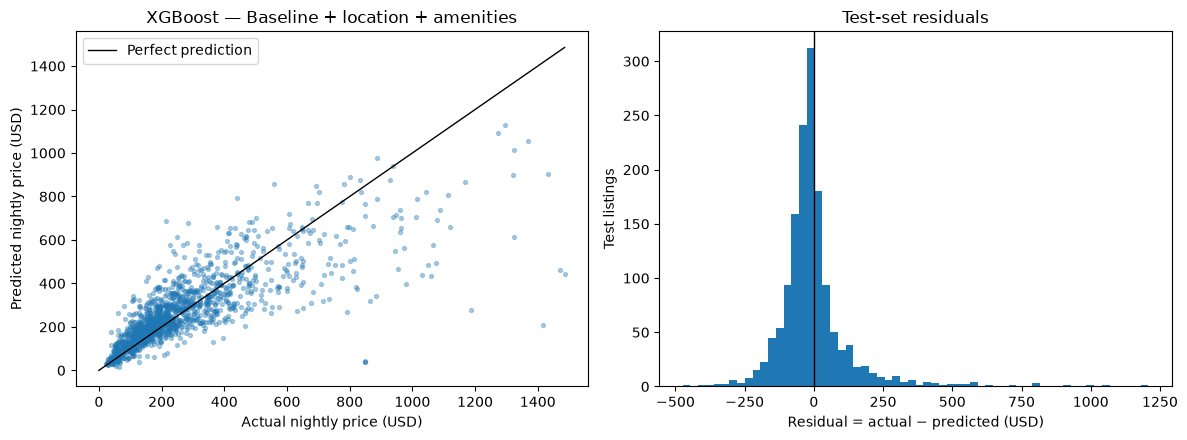

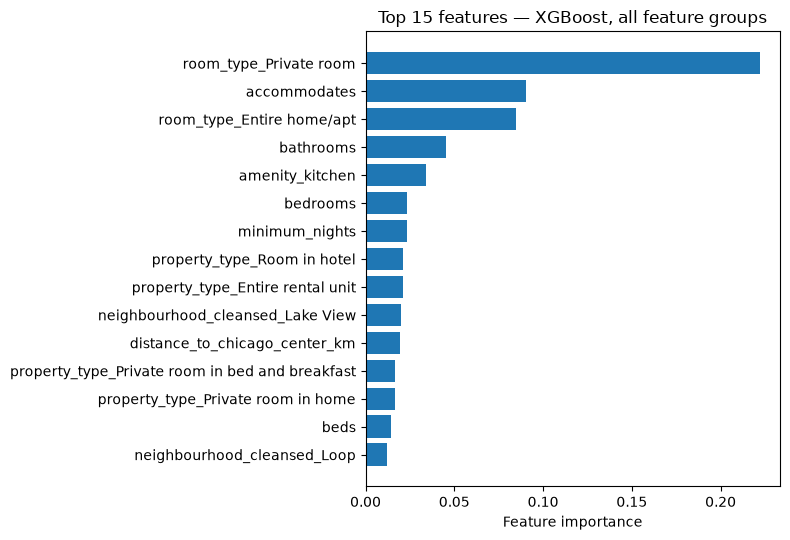

room_type_Private room                             0.2223
accommodates                                       0.0906
room_type_Entire home/apt                          0.0849
bathrooms                                          0.0455
amenity_kitchen                                    0.0343
bedrooms                                           0.0233
minimum_nights                                     0.0232
property_type_Room in hotel                        0.0209
property_type_Entire rental unit                   0.0209
neighbourhood_cleansed_Lake View                   0.0202
distance_to_chicago_center_km                      0.0197
property_type_Private room in bed and breakfast    0.0167
property_type_Private room in home                 0.0166
beds                                               0.0142
neighbourhood_cleansed_Loop                        0.0122


In [10]:
best_row = results_df.loc[results_df['MAE'].idxmin()]
best_key = (best_row['Feature set'], best_row['Model'])
best_preds = predictions[best_key]
residuals = y_test.to_numpy() - best_preds

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, best_preds, s=8, alpha=0.35)
limit = max(y_test.max(), best_preds.max())
axes[0].plot([0, limit], [0, limit], color='black', linewidth=1, label='Perfect prediction')
axes[0].set(xlabel='Actual nightly price (USD)', ylabel='Predicted nightly price (USD)',
            title=f'{best_key[1]} — {best_key[0]}')
axes[0].legend()
axes[1].hist(residuals, bins=60)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set(xlabel='Residual = actual − predicted (USD)', ylabel='Test listings', title='Test-set residuals')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'best_model_diagnostics.png', dpi=160)
plt.show()

tree_results = results_df[(results_df['Feature set'] == 'Baseline + location + amenities') & (results_df['Model'] != 'Linear Regression')]
tree_key = ('Baseline + location + amenities', tree_results.loc[tree_results['MAE'].idxmin(), 'Model'])
tree_pipeline = fitted[tree_key]
importances = pd.Series(
    tree_pipeline.named_steps['regressor'].feature_importances_,
    index=tree_pipeline.named_steps['preprocess'].get_feature_names_out(),
).sort_values(ascending=False)
importances.index = importances.index.str.replace(r'^(numeric|categorical)__', '', regex=True)
top_importances = importances.head(15)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top_importances.index[::-1], top_importances.to_numpy()[::-1])
ax.set(xlabel='Feature importance', title=f'Top 15 features — {tree_key[1]}, all feature groups')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'top_feature_importances.png', dpi=160)
plt.show()
print(top_importances.round(4).to_string())

## 9 — Saved outputs

Every output is written to the project's `results/` folder (resolved from `PROJECT_ROOT`, so it works whether the kernel starts in the project root or in `notebooks/`):

| File | Contents |
|---|---|
| `raw_column_overview.csv` | dtype, missing %, and distinct values for all raw columns |
| `filtering_log.csv` | rows removed at each cleaning step |
| `dataset_summary.csv` | dataset size and nightly-price statistics |
| `missingness.csv` | missing % of model inputs among retained listings |
| `amenity_prevalence.csv` | share of listings with each amenity indicator |
| `preliminary_results.csv` | MAE / RMSE / R² for all nine configurations |
| `feature_group_comparison.csv` | improvement from location and from amenities, per model and metric |
| `chicago_price_distribution.png`, `price_by_room_type.png`, `price_map.png` | EDA figures |
| `feature_group_mae.png`, `feature_group_metrics.png` | feature-group comparison figures |
| `best_model_diagnostics.png`, `top_feature_importances.png` | diagnostics for the best configuration |

These are preliminary, untuned results from a single train/test split. Report only numbers produced by running this notebook.